# CPU baixa significa VM ociosa?
## AIOps: perfis de utilização com PCA, K-Means e t-SNE
José Francisco Alves dos Santos | RMC AI Labs | Predict. Optimize. Evolve.

Continuação do laboratório Wine no mesmo repositório `chykynho/aiops-capacity-lab`.
Este notebook reaproveita a seção de VMs do laboratório compartilhado em 01/10/2026.
**Dados inteiramente sintéticos: 600 VMs e oito métricas.** Nenhum vCenter, inventário privado ou serviço cloud é acessado.

Objetivo: demonstrar por que CPU isolada é insuficiente e como explorar perfis antes de uma decisão.
Os quatro perfis foram desenhados no gerador; a separação observada não comprova que dados reais terão essa estrutura.


## 1. Preparar o ambiente WSL2 / VS Code
Na raiz do repositório existente, use o ambiente `aiops`. Se ele já existe, comece pela ativação; não o recrie.

Criação, somente se necessário:
```bash
conda create -n aiops python=3.12
```
Ativação, instalação pelo pyproject.toml e validação:
```bash
conda activate aiops
python -m pip install .
python -c "import sys; print(sys.executable); print(sys.version)"
python -c "import numpy, pandas, sklearn, matplotlib; print(numpy.__version__, pandas.__version__, sklearn.__version__, matplotlib.__version__)"
```
No VS Code, abra este notebook e selecione **Select Kernel → Python Environments → aiops (Python 3.12)**.
Execute a próxima célula e confirme o interpretador. Depois use **Restart Kernel and Run All**.
As dependências continuam exclusivamente no `pyproject.toml` do repositório.


In [1]:
import sys
import platform
import json
from pathlib import Path
from datetime import datetime, timezone
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

assert sys.version_info[:2] == (3, 12), "Selecione o kernel aiops com Python 3.12."
SEED = 42
N_VMS = 600
K = 4
VERSOES = {p: version(p) for p in ["numpy", "pandas", "scikit-learn", "matplotlib"]}
print("Python:", platform.python_version())
print("Versões:", VERSOES)
# O caminho do interpretador ajuda a validar localmente; não é exportado nos artefatos.
print("Interpretador:", sys.executable)

# Aceita execução com diretório de trabalho na raiz ou em notebooks/.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
OUT = ROOT / "artifacts" / "vm_perfis"
OUT.mkdir(parents=True, exist_ok=True)
print("Saídas: artifacts/vm_perfis/")
CORES = {0: "#16eee6", 1: "#f7c66b", 2: "#c5a1ff", 3: "#6fb6ff"}


Python: 3.12.15
Versões: {'numpy': '2.5.3', 'pandas': '2.3.3', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2'}
Interpretador: /home/francisco/miniconda3/envs/aiops/bin/python
Saídas: artifacts/vm_perfis/


## 2. Gerar as mesmas 600 VMs sintéticas
A semente, a ordem de geração e os parâmetros abaixo são preservados do laboratório original.
CPU e memória têm médias e p95; as demais métricas representam ocupação de disco, crescimento mensal, IOPS e latência.
Neste gerador, o p95 é uma aproximação simulada adicionada à média: não foi calculado de uma série temporal.
`perfil` serve apenas para gerar dados, **não entra no PCA nem no K-Means**.


In [2]:
rng = np.random.default_rng(SEED)
perfil = rng.choice([0, 1, 2, 3], size=N_VMS, p=[.32, .30, .22, .16])
centers = np.array([
    [12, 24, 35, 1.2, 50, 2],
    [65, 52, 49, 2.2, 240, 5],
    [34, 87, 66, 3.6, 160, 9],
    [78, 82, 86, 6.8, 470, 15],
], dtype=float)
raw = centers[perfil] + rng.normal(size=(N_VMS, 6)) * np.array([10, 9, 9, .8, 52, 2.2])
cpu_avg = np.clip(raw[:, 0], 1, 100)
mem_avg = np.clip(raw[:, 1], 1, 100)
disk = np.clip(raw[:, 2], 1, 99)
cpu_p95 = np.clip(cpu_avg + rng.uniform(5, 22, N_VMS), 1, 100)
mem_p95 = np.clip(mem_avg + rng.uniform(2, 13, N_VMS), 1, 100)
growth = np.clip(raw[:, 3], 0, 15)
iops = np.clip(raw[:, 4], 1, None)
latency = np.clip(raw[:, 5], .3, None)
vms = pd.DataFrame({
    "vm_id": [f"VM-{i:04d}" for i in range(1, N_VMS + 1)],
    "cpu_media_pct": cpu_avg,
    "cpu_p95_pct": cpu_p95,
    "mem_media_pct": mem_avg,
    "mem_p95_pct": mem_p95,
    "disco_usado_pct": disk,
    "crescimento_disco_pct_mes": growth,
    "iops_medios": iops,
    "latencia_disco_ms": latency,
})
features = [c for c in vms.columns if c != "vm_id"]
assert len(features) == 8 and len(vms) == 600
assert vms.vm_id.is_unique and np.isfinite(vms[features].to_numpy()).all()
print(vms.head(3).round(2).to_string(index=False))


  vm_id  cpu_media_pct  cpu_p95_pct  mem_media_pct  mem_p95_pct  disco_usado_pct  crescimento_disco_pct_mes  iops_medios  latencia_disco_ms
VM-0001          46.48        58.36          84.73        89.17            69.27                       1.67        99.87               8.35
VM-0002          54.28        73.84          58.43        67.91            66.98                       1.26       196.45               5.52
VM-0003          94.11       100.00          71.00        77.26            88.24                       8.26       384.11              12.18


## 3. Padronizar, reduzir e agrupar
StandardScaler evita que escalas como IOPS dominem a distância apenas pela unidade.
PCA retém mais de 90% da variância e K-Means é ajustado nesse espaço reduzido.
`k=4` é uma escolha didática, não uma seleção validada para infraestrutura real.
Não há teste de generalização: é uma exploração dos 600 registros, não uma avaliação preditiva fora da amostra.
Silhouette descreve separação geométrica; não mede economia, disponibilidade ou causa raiz.


In [3]:
scale_vm = StandardScaler().fit(vms[features])
X_vm = scale_vm.transform(vms[features])
pca_vm = PCA(n_components=0.90, svd_solver="full").fit(X_vm)
X_vm_pca = pca_vm.transform(X_vm)
km_vm = KMeans(n_clusters=K, random_state=SEED, n_init=10).fit(X_vm_pca)
vms["cluster_bruto"] = km_vm.labels_

# IDs de K-Means são arbitrários. Padronizamos apenas os nomes para comparar
# com a demonstração anterior: CPU em ordem crescente -> IDs 0, 1, 3, 2.
# Isso NÃO muda a composição dos grupos nem alimenta o ajuste do modelo.
ordem = vms.groupby("cluster_bruto")["cpu_media_pct"].median().sort_values().index
mapa_ids = {int(bruto): rotulo for bruto, rotulo in zip(ordem, [0, 1, 3, 2])}
vms["cluster"] = vms["cluster_bruto"].map(mapa_ids)
variancia = float(pca_vm.explained_variance_ratio_.sum())
silhouette = float(silhouette_score(X_vm_pca, vms["cluster"]))
print(f"8 métricas → {pca_vm.n_components_} componentes; variância {variancia:.1%}; silhouette {silhouette:.3f}")
print("Correspondência IDs brutos → IDs apresentados:", mapa_ids)


8 métricas → 3 componentes; variância 93.6%; silhouette 0.672
Correspondência IDs brutos → IDs apresentados: {0: 0, 1: 1, 3: 3, 2: 2}


## 4. Voltar às métricas originais
Calculamos **medianas entre VMs de cada grupo**. A coluna CPU média é uma característica de cada VM; a tabela resume essa característica pela mediana do grupo.
Compare CPU e memória antes de interpretar utilização. Grupo com CPU moderada e memória alta não pode ser julgado apenas pela CPU.


         cpu_media_pct  cpu_p95_pct  mem_media_pct  mem_p95_pct  disco_usado_pct  crescimento_disco_pct_mes  iops_medios  latencia_disco_ms  quantidade
cluster                                                                                                                                                
0                 12.7         25.6           23.3         30.4             35.3                        1.2         52.3                2.0         202
1                 32.6         46.6           85.4         92.1             66.6                        3.6        162.1                9.1         144
2                 79.7         90.7           80.0         87.6             83.5                        6.9        469.0               14.8          86
3                 65.4         78.2           52.1         59.5             48.7                        2.2        251.5                5.2         168


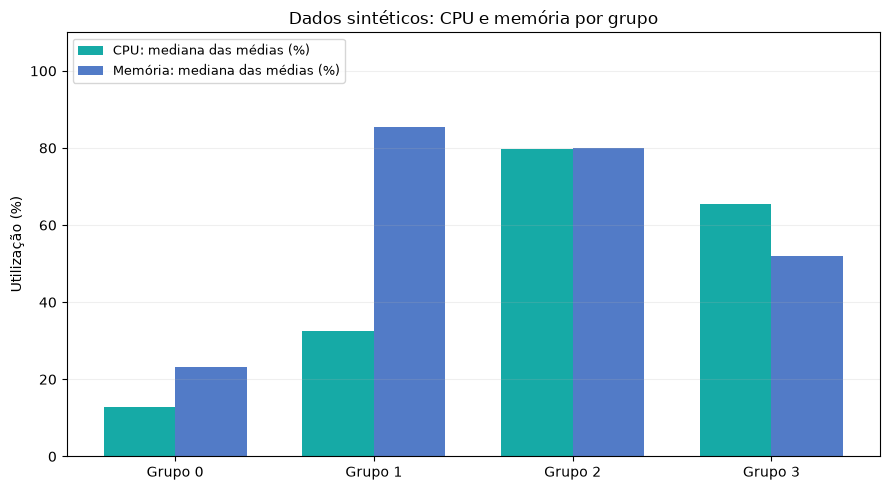

In [4]:
resumo = vms.groupby("cluster")[features].median().round(1)
resumo["quantidade"] = vms.groupby("cluster").size()
print(resumo.to_string())

fig, ax = plt.subplots(figsize=(9, 5))
pos = np.arange(K)
ax.bar(pos - .18, resumo.cpu_media_pct, width=.36, label="CPU: mediana das médias (%)", color="#16aaa6")
ax.bar(pos + .18, resumo.mem_media_pct, width=.36, label="Memória: mediana das médias (%)", color="#527bc7")
ax.set(xticks=pos, xticklabels=[f"Grupo {k}" for k in resumo.index], ylim=(0, 110),
       ylabel="Utilização (%)", title="Dados sintéticos: CPU e memória por grupo")
ax.legend(loc="upper left", fontsize=9)
ax.grid(axis="y", alpha=.2)
fig.tight_layout()
fig.savefig(OUT / "cpu_memoria_mediana.png", dpi=180)
plt.show()


## 5. Mapa PCA em duas dimensões
O agrupamento anterior usa três componentes nesta demonstração; o mapa usa dois apenas para visualização.
As cores indicam os mesmos grupos. Uma projeção 2D pode ocultar diferenças.
Os eixos são combinações das oito métricas padronizadas, não porcentagens de CPU/memória.


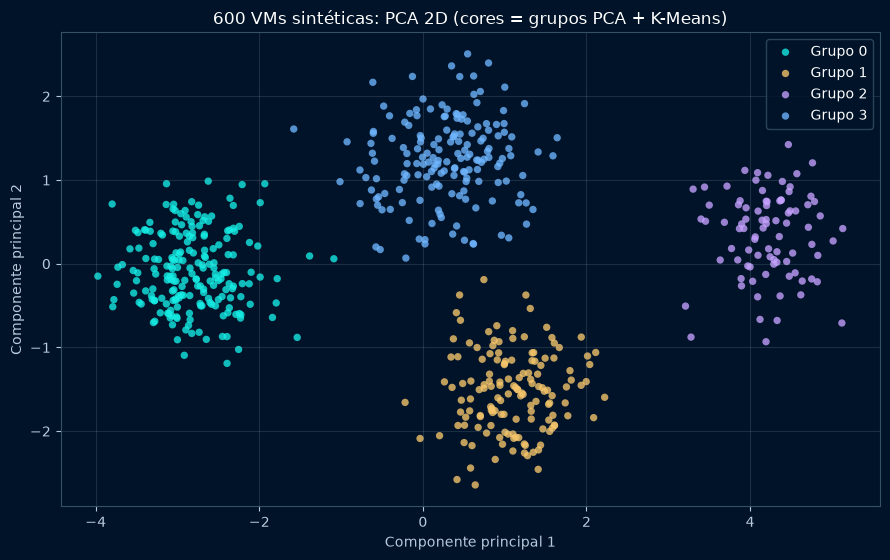

In [5]:
proj_2d = PCA(n_components=2).fit_transform(X_vm)
fig, ax = plt.subplots(figsize=(9, 5.7), facecolor="#001329")
ax.set_facecolor("#001329")
for k in range(K):
    mask = vms["cluster"].eq(k)
    ax.scatter(proj_2d[mask, 0], proj_2d[mask, 1], s=28,
               color=CORES[k], alpha=.78, edgecolors="none", label=f"Grupo {k}")
ax.set(xlabel="Componente principal 1", ylabel="Componente principal 2",
       title="600 VMs sintéticas: PCA 2D (cores = grupos PCA + K-Means)")
ax.tick_params(colors="#b8cadb")
ax.xaxis.label.set_color("#b8cadb")
ax.yaxis.label.set_color("#b8cadb")
ax.title.set_color("white")
for spine in ax.spines.values():
    spine.set_color("#365065")
ax.legend(facecolor="#001329", labelcolor="white", edgecolor="#365065")
ax.grid(alpha=.15, color="#b8cadb")
fig.tight_layout()
fig.savefig(OUT / "pca_perfis_vms.png", dpi=180, facecolor=fig.get_facecolor())
plt.show()


## 6. t-SNE: outra visualização, sem reajustar os grupos
Usamos as oito métricas padronizadas para explorar vizinhanças em t-SNE.
As cores continuam sendo os grupos encontrados por PCA + K-Means. Não ajustamos K-Means no t-SNE.
Distâncias entre ilhas, área e orientação do mapa não são medidas operacionais diretas.
O TSNE padrão do scikit-learn não oferece `transform` para posicionar novas VMs nesse mapa já ajustado.


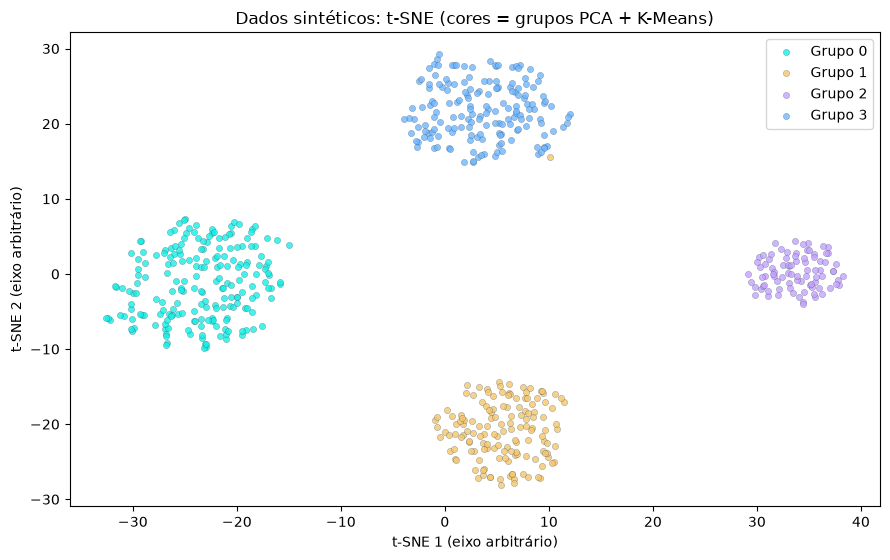

In [6]:
vm_tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto",
               random_state=SEED, max_iter=700).fit_transform(X_vm)
fig, ax = plt.subplots(figsize=(9, 5.7))
for k in range(K):
    mask = vms["cluster"].eq(k)
    ax.scatter(vm_tsne[mask, 0], vm_tsne[mask, 1], color=CORES[k],
               s=20, alpha=.8, edgecolors="#244050", linewidths=.2, label=f"Grupo {k}")
ax.set(title="Dados sintéticos: t-SNE (cores = grupos PCA + K-Means)",
       xlabel="t-SNE 1 (eixo arbitrário)", ylabel="t-SNE 2 (eixo arbitrário)")
ax.legend()
fig.tight_layout()
fig.savefig(OUT / "tsne_perfis_vms.png", dpi=180)
plt.show()


## 7. Conferir a demonstração de referência
Os números abaixo vieram da execução salva do laboratório e da tabela usada no carrossel.
A conferência não impõe resultados ao modelo: compara a saída efetivamente calculada com a referência.
Diferenças entre versões podem alterar o ajuste; nesse caso, pare e investigue antes de divulgar números.


In [7]:
referencia = pd.DataFrame({
    "quantidade": [202, 144, 86, 168],
    "cpu_media_pct": [12.7, 32.6, 79.7, 65.4],
    "mem_media_pct": [23.3, 85.4, 80.0, 52.1],
}, index=pd.Index([0, 1, 2, 3], name="cluster"))
assert pca_vm.n_components_ == 3
assert round(variancia * 100, 1) == 93.6
assert np.isclose(silhouette, .672, atol=.0005)
assert np.array_equal(resumo.quantidade.to_numpy(), referencia.quantidade.to_numpy())
np.testing.assert_allclose(resumo[["cpu_media_pct", "mem_media_pct"]],
                           referencia[["cpu_media_pct", "mem_media_pct"]], atol=.05, rtol=0)
assert proj_2d.shape == vm_tsne.shape == (600, 2)
assert np.isfinite(vm_tsne).all()
print("CONFERIDO: 600 VMs, 8 métricas, 3 componentes, 93,6% de variância e medianas da referência.")


CONFERIDO: 600 VMs, 8 métricas, 3 componentes, 93,6% de variância e medianas da referência.


## 8. Salvar evidências reproduzíveis
CSV das VMs, resumo, mapas e JSON com parâmetros/versões. As exportações usam IDs sintéticos e caminhos relativos.
Nenhuma ação de rightsizing ou desligamento é implementada.


In [8]:
vms.to_csv(OUT / "vm_clusters_dimensionalidade.csv", index=False, encoding="utf-8")
resumo.to_csv(OUT / "medianas_por_grupo.csv", encoding="utf-8")
pd.DataFrame({"vm_id": vms.vm_id, "pca_1": proj_2d[:, 0], "pca_2": proj_2d[:, 1],
              "tsne_1": vm_tsne[:, 0], "tsne_2": vm_tsne[:, 1], "cluster": vms.cluster}).to_csv(
    OUT / "projecoes_vms.csv", index=False)
evidencias = {
    "data_utc": datetime.now(timezone.utc).isoformat(),
    "tipo_dado": "sintético", "n_vms": N_VMS, "features": features,
    "parametros": {"seed": SEED, "k": K, "n_init": 10, "pca_variancia_alvo": .90,
                   "pca_svd_solver": "full", "tsne_perplexity": 30, "tsne_max_iter": 700},
    "python": platform.python_version(), "versoes": VERSOES,
    "componentes_pca": int(pca_vm.n_components_), "variancia_pca": variancia,
    "silhouette_pca": silhouette, "mapa_ids": mapa_ids,
    "validacao_referencia": "conferida pelas verificações da célula anterior",
    "limite": "Exploração sintética; não valida decisão operacional nem generalização.",
}
(OUT / "evidencias_execucao.json").write_text(
    json.dumps(evidencias, ensure_ascii=False, indent=2), encoding="utf-8")
print("Arquivos produzidos:")
for p in sorted(OUT.iterdir()):
    print(p.name)


Arquivos produzidos:
cpu_memoria_mediana.png
evidencias_execucao.json
medianas_por_grupo.csv
pca_perfis_vms.png
projecoes_vms.csv
tsne_perfis_vms.png
vm_clusters_dimensionalidade.csv


## O que esta demonstração sustenta
- CPU e memória contam partes diferentes da história: no grupo 1, medianas de 32,6% e 85,4%.
- PCA reduz dimensionalidade; K-Means agrupa no PCA; t-SNE explora vizinhanças separadamente.
- O mapa e as tabelas orientam investigação. Não comprovam desperdício, causa raiz ou economia.
- Antes de alterar recursos: métricas originais, picos reais, histórico, criticidade, estabilidade e política operacional.

A demonstração foi executada em Python 3.12.14 no ambiente de preparação em 09/10/2026.
Isso não é evidência de execução no WSL do autor; a validação nesse ambiente é uma etapa separada.

## Fontes oficiais consultadas em 09/10/2026
- [PCA](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html)
- [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html)
- [KMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html)
- [TSNE](https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html)
